# 项目：可视化帕默群岛企鹅数据

## 分析目标

此数据分析报告的目的是对帕默群岛上企鹅样本的相关变量进行可视化，从而探索和分析种类、性别、所在岛屿等因素，与企鹅的身体属性，包括体重、嘴峰长度和深度、鳍的长度，之间的关系。

## 简介

原始数据`Penguins.csv`包括334个收集自南极洲帕尔默群岛的3个岛屿上的企鹅样本，以及企鹅相关属性数据，包括种类名、所在岛、嘴峰长度、嘴峰深度、鳍长度、体重、性别。

`Penguins.csv`每列的含义如下：
- species：企鹅的种类
- island：企鹅所在岛
- culmen_length_mm：企鹅嘴峰的长度（单位为毫米）
- culmen_depth_mm：企鹅嘴峰的深度（单位为毫米）
- flipper_length_mm：企鹅鳍的长度（单位为毫米）
- body_mass_g：企鹅体重（单位为克）
- sex：企鹅性别

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
od=pd.read_csv(r"C:\Users\30338\Desktop\数据处理学习\4数据可视化\penguins.csv")
od.head(10)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,FEMALE
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,MALE
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


## 一、数据评估和清理  
在评估和清理这一部分中，将对在上一部分建立的odDataFrame所包含的数据进行评估和清理。  
主要从两个方面进行：结构和内容，即整齐度和干净度。  
数据结构性问题指不符合“每个变量为一列，每个观察值为一行，每种类型的观察单位为一个表格”这三个标准；  
数据内容性问题包括存在丢失数据、重复数据、无效数据等。

### 为了区分清理数据和原数据，特将其copy原数据，创建cd来代表清理后的数据集

In [3]:
cd=od.copy()
cd.head(10)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,FEMALE
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,MALE
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


### 1.数据整齐度  
从表上预选的数据来看，该表的数据结构符合“每个变量为一列，每个观察值为一行，每种类型的观察单位为一个表格”这三个标准；  
因此不存在结构性问题，不对其进行结构性处理。

### 2.数据干净度

##### 通过info来了解基本数据情况

In [4]:
cd.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


##### 从info的输出结果来看，共有culmen_length_mm、culmen_depth_mm、flipper_length_mm、body_mass_g这四类数据存在空缺值，将在后面进行评估清理；  
其次，从输出的数据类型上看：species、island、sex都属于分类数据、因此可以将数据类型转换为category

In [5]:
cd["species"]=cd["species"].astype("category")
cd["island"]=cd["island"].astype("category")
cd["sex"]=cd["sex"].astype("category")

##### 完成数据类型转换后再通过info来进行检查。

In [6]:
cd.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   species            344 non-null    category
 1   island             344 non-null    category
 2   culmen_length_mm   342 non-null    float64 
 3   culmen_depth_mm    342 non-null    float64 
 4   flipper_length_mm  342 non-null    float64 
 5   body_mass_g        342 non-null    float64 
 6   sex                334 non-null    category
dtypes: category(3), float64(4)
memory usage: 12.0 KB


#### 2.1缺失数据处理  
从输出结果上看共有culmen_length_mm、culmen_depth_mm、flipper_length_mm、body_mass_g、sex这五类数据存在空缺值，接下来进行评估清理；
先提取出缺失变量的观察值进行查看

In [7]:
cd.query("culmen_length_mm.isna()")

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


##### 可以发现，culmen_length_mm为空值的行，除了索引、种类、所属岛屿以外的其他行也是空值，这无法为数据分析提供有价值的信息，因此可以将这两行删除。

In [8]:
cd.drop(3,inplace=True)
cd.drop(339,inplace=True)

##### 根据上面的输出结果可知当前还会剩下sex存在空值，现在对sex的缺值进行查看

In [9]:
cd.query("sex.isnull()")

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN


##### 从输出结果可知，sex为空值的列的其他观察值仍旧有其分析意义，而sex不会对分析结果产生影响；  
并且pandas和matplotlib、seaborn在绘图时会自动忽略缺失值，因此可以不对其进行处理。

#### 2.2处理重复数据  
根据变量含义和内容来看，这些变量的数值允许存在重复情况，因此不需要进行重复值的处理，否则会影响分析结果。

#### 2.3 处理不一致数据  
不一致数据可能存在任何变量中，目前要查看是否存在不同值实际指代同一目标的情况。

In [10]:
cd["species"].value_counts()

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

In [11]:
cd["island"].value_counts()

island
Biscoe       167
Dream        124
Torgersen     51
Name: count, dtype: int64

In [12]:
cd["sex"].value_counts()

sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64

##### sex变量列存在一个英文句号导致不一致，因此需要对其进行处理,并进行查看。

In [13]:
cd["sex"]=cd["sex"].replace(".",np.nan)
cd=cd.dropna()
cd["sex"].value_counts()

sex
MALE      168
FEMALE    165
.           0
Name: count, dtype: int64

##### 现在英文句号被替换为空值，因此不存在不一致数据了。  
但是这个列依旧存在，此时可以在后面通过筛选来重新赋值cdx来过滤掉这一遗漏。

#### 2.4 处理无效或错误数据  
可以通过DF的describe方法来对数值统计信息进行快速了解。

In [14]:
cd.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057
std,5.468668,1.969235,14.015765,805.215802
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.600000,18.700000,213.000000,4775.000000
max,59.600000,21.500000,231.000000,6300.000000


#### 从统计信息上看，cd不存在脱离现实意义的数据。因此就不进行无效或错误数据的清洗，数据评估和清洗流程结束

## 二、探索数据  
接下来将通过数据可视化来进行探索和分析，从图表中获取企鹅样本数据的相关洞察。

In [15]:
#在绘图之前，可以先设置色盘，此后所有图表都会以该色盘进行绘制
sns.set_palette("pastel")
cd

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


### 1.单变量探索  

#### 1.1 企鹅种类比例  
可以对企鹅种类的数量进行饼图绘制，现在面临的问题就是目前没有种类对应的数量汇总，  
此时就需要通过groupby来进行聚合运算来得出汇总数据  
可以从表中选取一个没有缺失值的列来计数

In [16]:
cds=cd.groupby("species")["island"].count()
#等同于cds=cd["species"].value_counts()
cds

species
Adelie       146
Chinstrap     68
Gentoo       119
Name: island, dtype: int64

##### 接下来以cds为基准绘制饼图

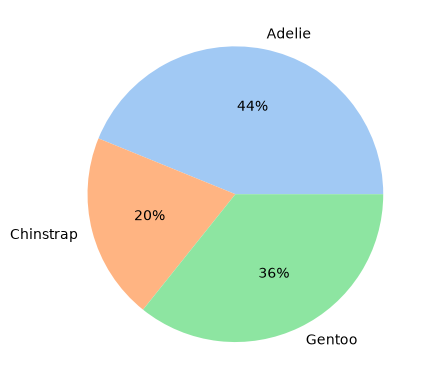

In [17]:
plt.pie(cds,autopct="%.0f%%",labels=cds.index)#因为标签索引恰好对应数据，因此可以直接用索引来给labels赋值
plt.show()

##### 接下来查看企鹅所属岛屿比例

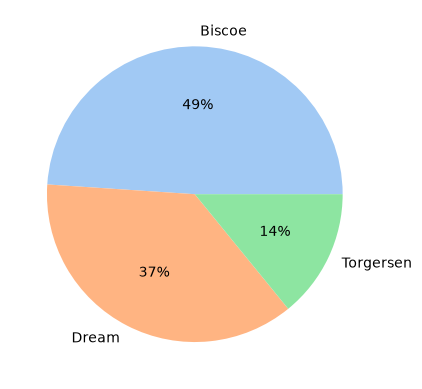

In [18]:
cdi=cd["island"].value_counts()
plt.pie(cdi,autopct="%.0f%%",labels=cdi.index)
plt.show()

##### 接下来对企鹅的性别比例进行绘图

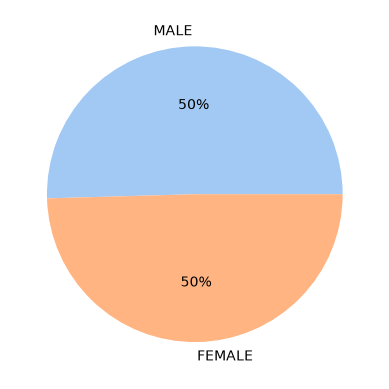

In [21]:
cdx=cd["sex"].value_counts()
#过滤掉数量为0的类别
cdx=cdx[cdx>0]
plt.pie(cdx,autopct="%.0f%%",labels=cdx.index)
plt.show()

#### 1.2不同岛上的企鹅种类数量
该图表应该由企鹅种类和归属岛屿这两个分类变量组成，以及样本数这个数值变量，因此可以使用复合条形图。  
还可以通过使用countplot这个计数图来统计分类变量的数值个数；并绘制出图表。

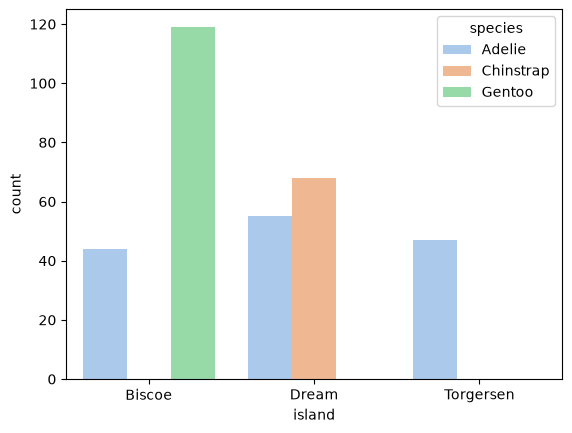

In [23]:
sns.countplot(cd,x="island",hue="species")
plt.show()

#### 1.3不同岛屿上企鹅的性别数量

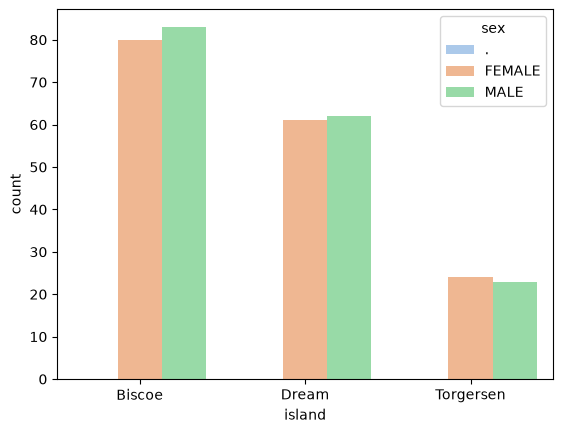

In [24]:
sns.countplot(cd,x="island",hue="sex")
plt.show()

### 探索数值变量  
查看数值之间的相关关系,可以使用成对图pairplot

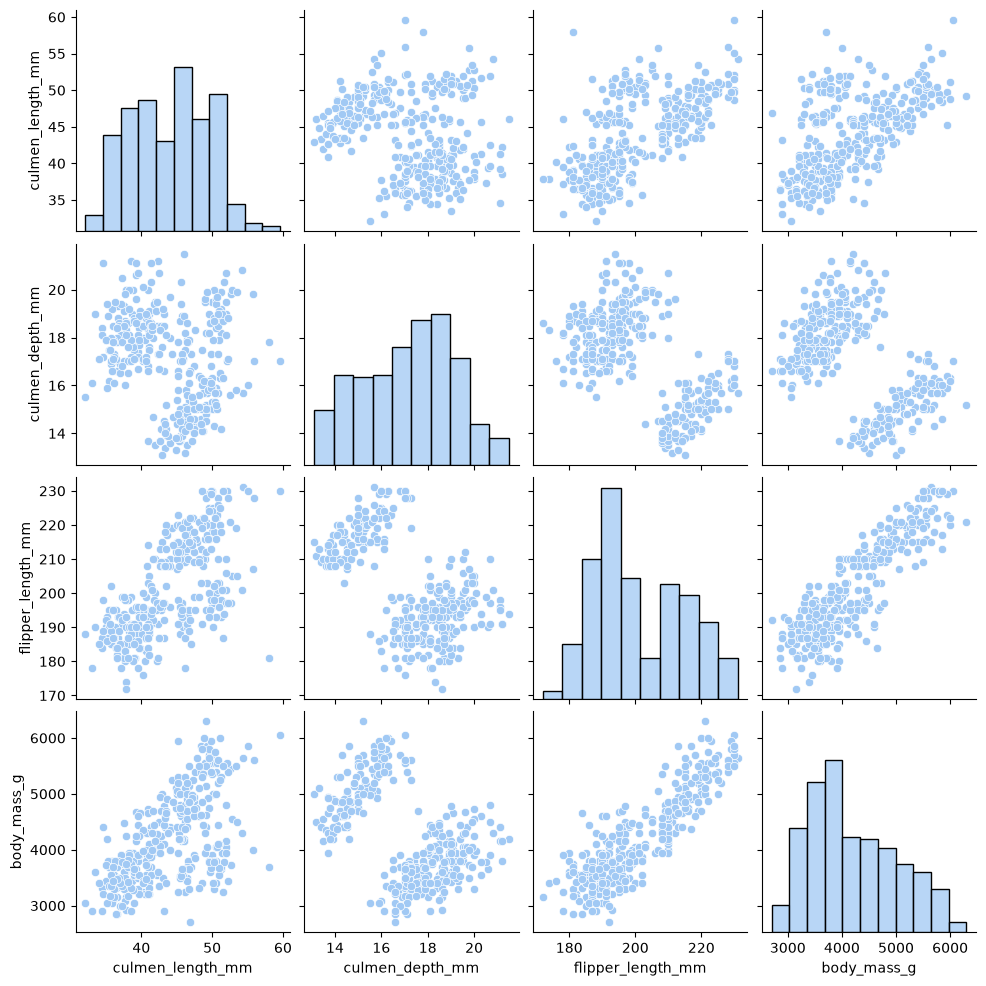

In [25]:
sns.pairplot(cd)
plt.show()

##### 从直方图来看，企鹅样本的嘴峰长度、嘴峰深度、鳍长度、体重的分布不是正态分布。  
一方面说明，这里面可能包含了多组存在差异的样本数据，另一方面也说明样本数不够大。  
另外可以在散点图中看出明显的多个集群，可能与某些因素有关，比如企鹅种类、性别，因此可以对对比进行进一步的分类。

#### 根据种类查看数值之间的相关关系

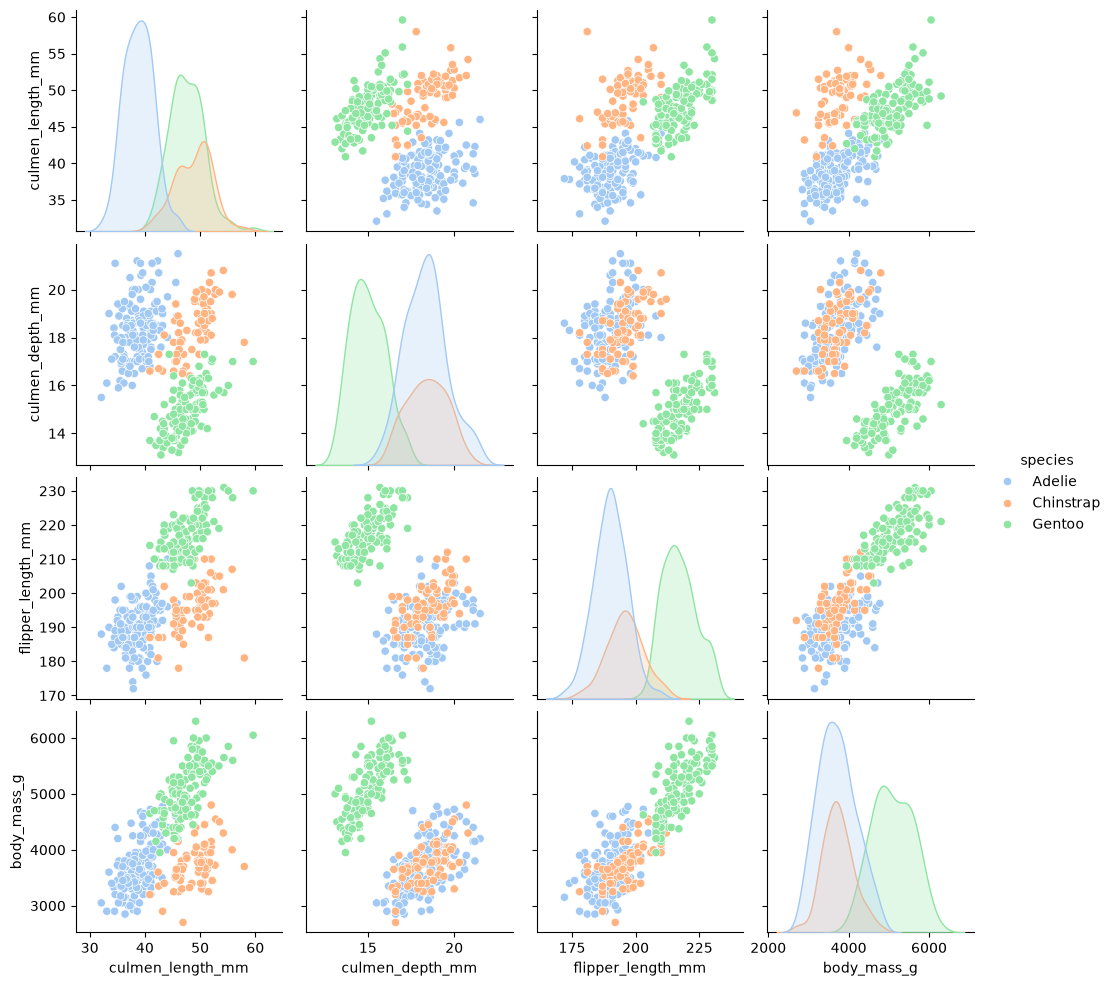

In [27]:
sns.pairplot(cd,hue="species")
plt.show()

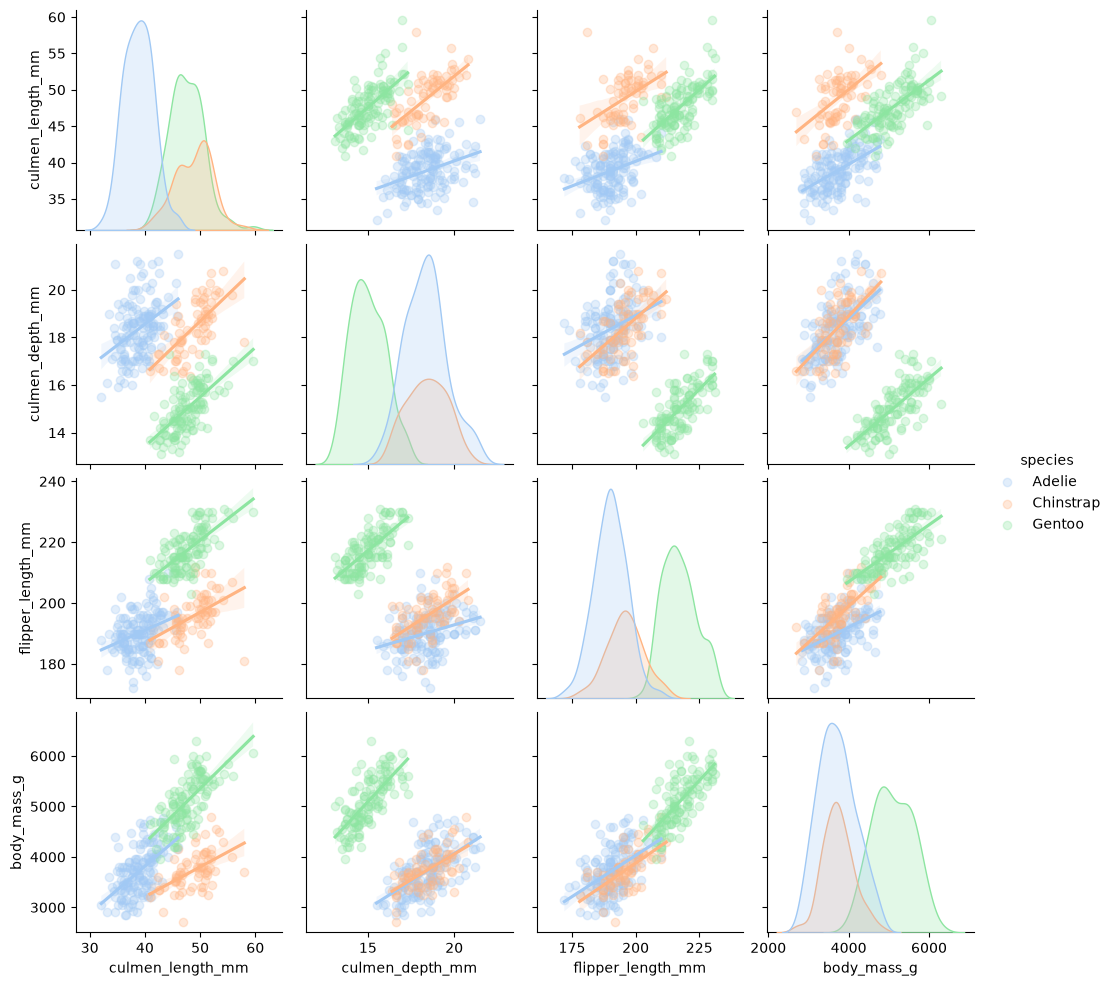

In [34]:
sns.pairplot(cd,hue="species",kind="reg",plot_kws={"scatter_kws":{"alpha":0.3}})
#reg表示regresssion line：回归线
plt.show()

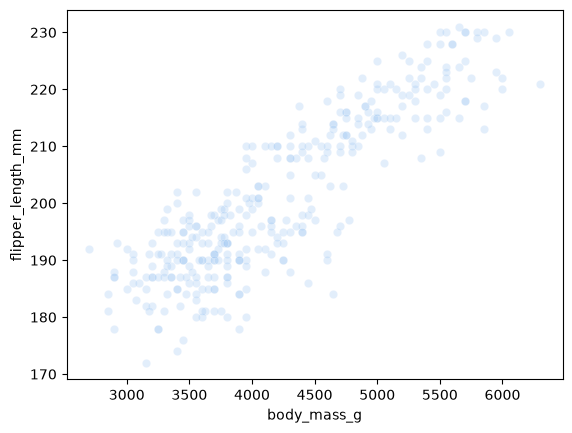

In [31]:
#平时绘图可以直接加入alpha参数，例如：
sns.scatterplot(cd,x="body_mass_g",y="flipper_length_mm",alpha=0.3)
plt.show()

##### 散点图结合线性回归线来看，同类企鹅的属性数据之间均呈线性正比，即嘴峰越长，嘴峰越深，鳍越长，体重越重，嘴峰越短，嘴峰越浅，鳍越短，体重越轻。

##### 从密度图的分布来看，可以得到以下关于样本的发现：
Chinstrap和Gentoo的嘴峰长度范围较为接近，而Adelie的嘴峰长度更短。  
Adelie和Chinstrap的嘴峰深度范围较为接近，而Gentoo的嘴峰深度更短。  
Adelie的鳍长度最短，Chinstrap中等，而Gentoo的鳍长度嘴长。  
Adelie和Chinstrap的体重范围较为接近，而Gentoo的体重更大。  
但不同种类的属性数值否存在统计显著性差异，仍然需要进行假设检验后才能得到结论。

#### 根据性别来查看数值之间的相关关系

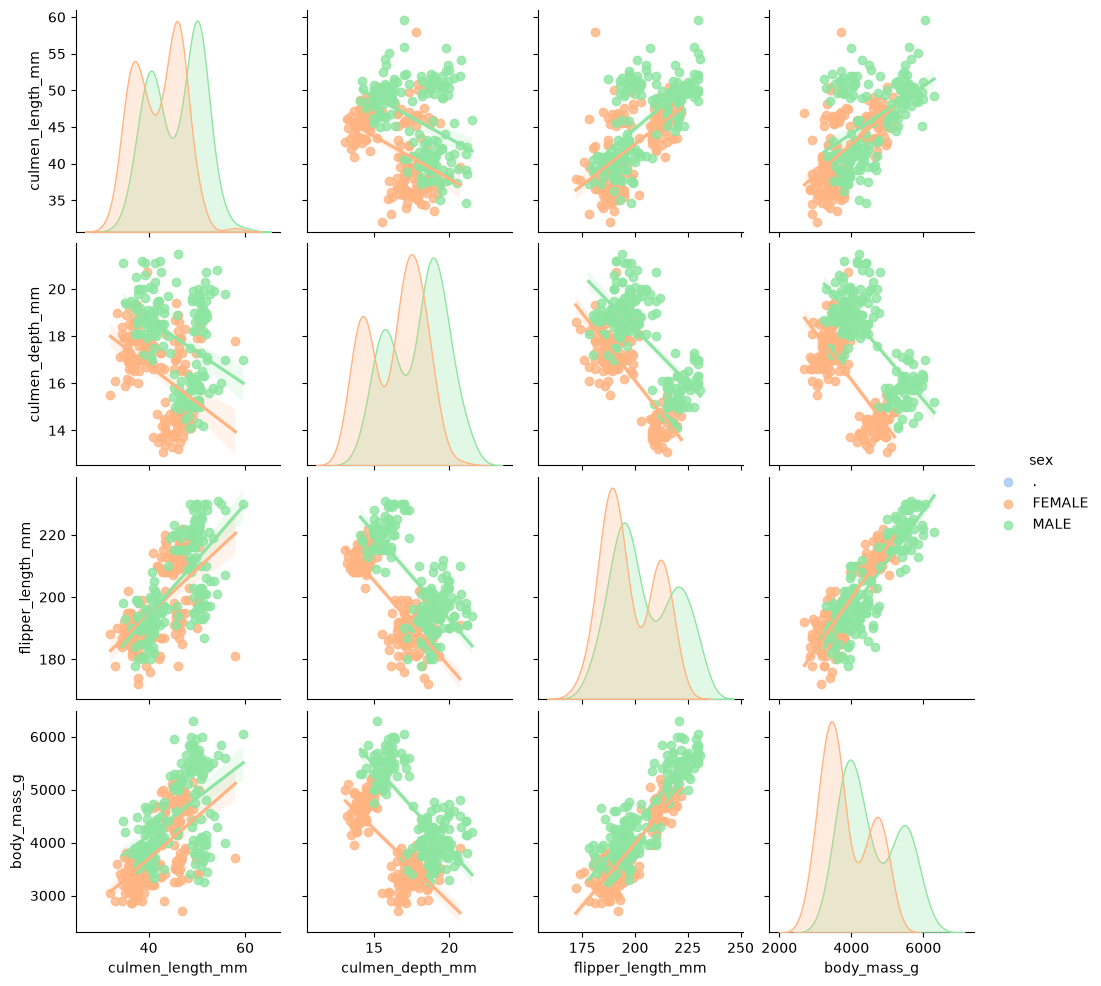

In [33]:
sns.pairplot(cd,hue="sex",kind="reg")
plt.show()

#### 由图可知，雄性企鹅的数值基本上全都高于雌性企鹅。